# 基于颜色统计与方向梯度特征的图像无监督聚类比较研究

**数据挖掘导论 2026 大作业 · 任务1**

## 摘要

针对包含 600 张图像、6 个语义类别的课程数据集，本文比较两种特征表示下的图像聚类方案：
方法 A 采用三通道平均颜色统计，方法 B 采用方向梯度直方图（Histogram of Oriented Gradients，HOG）。
两种方案均使用相同配置的 K-Means，以减少聚类算法差异对比较的干扰。实验依次完成无标签数据检查、
两条独立方法流程的特征提取与模型拟合、统一的外部及内部评价，并报告五个固定随机种子下的稳定性结果。
当前数据上的主要实验中，颜色方案的 ACC 为 77.83%，HOG 方案的 ACC 为 100.00%。
结果表明，在本数据及所选参数下，包含局部空间结构的 HOG 表示更符合给定类别划分；该结论的适用范围限于当前数据集。

**关键词：** 无监督学习；图像聚类；特征表示；HOG；K-Means

## 目录

1. 研究问题与形式化描述
2. 数据与公共实验协议
3. 方法 A：平均颜色统计与 K-Means
4. 方法 B：HOG 表示与 K-Means
5. 统一评价协议与分方法结果
6. 对照实验与随机初始化稳定性
7. 讨论与局限
8. 结论与复现记录
9. 参考文献

方法 A 与方法 B 分别构成完整的“特征提取—模型训练—簇结构展示”流程。
两者的聚类算法相同，本文比较的是特征表示方案，而非两种不同的训练算法。
运行环境和数据放置方式见 `README.md`。

## 1. 研究问题与形式化描述

设无标签图像集合为 $\mathcal I=\{I_i\}_{i=1}^{N}$，其中 $N=600$。
给定特征映射 $\phi_m:\mathcal I\rightarrow\mathbb R^{d_m}$，获得方法 $m$ 的特征矩阵
$X^{(m)}=[\phi_m(I_1),\ldots,\phi_m(I_N)]^\top$。
根据题目给出的类别数量设 $K=6$，求簇指派 $z_i^{(m)}\in\{0,\ldots,K-1\}$ 及中心 $\mu_k^{(m)}$：

$$
\min_{\{\mu_k^{(m)}\},\{z_i^{(m)}\}}
\sum_{i=1}^{N}\left\|\phi_m(I_i)-\mu_{z_i^{(m)}}^{(m)}\right\|_2^2.
$$

K-Means 通过最近中心指派与簇均值更新交替优化上述目标 [1, 5]。
簇编号仅标识分组，不预先对应类别名称。已知 $K$ 属于任务先验；训练过程不读取单张图像的真实类别，也不施加每簇 100 张的约束。

本文考察的问题为：在固定聚类算法与主要超参数时，颜色统计与局部方向梯度两种表示，分别能在多大程度上恢复课程数据的语义类别结构？

## 2. 数据与公共实验协议

本节规定两种方法共用的数据索引、随机性控制、聚类设置和记录方式。方法专属的预处理与特征参数在第3、4节分别说明。

### 2.1 软件环境与公共参数

主要实验固定随机种子为42；稳定性实验使用预先指定的0、1、7、21、42。`n_init=10` 表示每个种子尝试十次中心初始化，并根据组内平方距离和保留结果。

In [ ]:
from pathlib import Path
from collections import Counter
from importlib.metadata import version
from time import perf_counter
import csv
import hashlib
import io
import json
import os
import platform
import zipfile

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps, ImageStat
from IPython.display import Image as NotebookImage, Markdown, display
from scipy.optimize import linear_sum_assignment
from skimage.feature import hog
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score



def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "image_clustering.ipynb").is_file() and (candidate / "requirements.txt").is_file():
            return candidate
    raise FileNotFoundError("请在本仓库目录内打开并运行 image_clustering.ipynb。")


PROJECT_ROOT = find_project_root()
DATA_PATH = Path(os.environ.get("CLUSTER_DATA_PATH", "data/Cluster.zip")).expanduser()
if not DATA_PATH.is_absolute():
    DATA_PATH = PROJECT_ROOT / DATA_PATH
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

CONFIG = {
    "n_clusters": 6,
    "primary_seed": 42,
    "stability_seeds": [0, 1, 7, 21, 42],
    "kmeans": {"init": "k-means++", "n_init": 10, "max_iter": 300, "tol": 1e-4, "algorithm": "lloyd"},
}

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110,
})



METHOD_DIRS = {
    "mean_rgb": RESULTS_DIR / "method_a_mean_rgb",
    "hog": RESULTS_DIR / "method_b_hog",
}
COMPARISON_DIR = RESULTS_DIR / "comparison"
for directory in [*METHOD_DIRS.values(), COMPARISON_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
METHOD_NAMES = {"mean_rgb": "A: Mean RGB + K-Means", "hog": "B: HOG + K-Means"}

def write_csv(path, rows, fieldnames):
    with path.open("w", encoding="utf-8-sig", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)


def show_table(rows, columns):
    # columns 是 (字段名, 显示名)；结果只包含本实验生成的简单数值和类别名。
    lines = ["| " + " | ".join(title for _, title in columns) + " |"]
    lines.append("| " + " | ".join("---" for _ in columns) + " |")
    for row in rows:
        values = []
        for key, _ in columns:
            value = row[key]
            values.append(f"{value:.4f}" if isinstance(value, (float, np.floating)) else str(value))
        lines.append("| " + " | ".join(values) + " |")
    display(Markdown("\n".join(lines)))



packages = ["numpy", "scipy", "scikit-learn", "scikit-image", "Pillow", "matplotlib", "ipykernel", "nbformat", "nbclient"]
environment = {"python": platform.python_version(), "packages": {name: version(name) for name in packages}}
print("Python:", environment["python"])
print("数据文件:", DATA_PATH.name)
print("主实验种子:", CONFIG["primary_seed"])


### 2.2 数据组织与完整性检查

数据来自课程提供的 `Cluster.zip`，图像位于 `Cluster/dataset/`；题目说明包含 bottle、cable、leather、pill、tile、transistor 六类，每类100张。
建立按文件名排序的统一索引，检查数量与文件名唯一性，并记录压缩包的 SHA-256 摘要。
本阶段只读取图像目录与像素；类别标签文件在两种方法的训练均完成后才加载。

In [ ]:
if not DATA_PATH.is_file():
    raise FileNotFoundError("请按 README 将作业数据放到 data/Cluster.zip，或设置 CLUSTER_DATA_PATH。")

with zipfile.ZipFile(DATA_PATH) as archive:
    image_names = sorted(
        name for name in archive.namelist()
        if name.startswith("Cluster/dataset/") and name.lower().endswith(".png")
    )

filenames = [Path(name).name for name in image_names]
if len(image_names) != 600 or len(set(filenames)) != len(filenames):
    raise ValueError("预期为 600 张无重复文件名的图片，请检查 Cluster.zip 是否为完整作业数据。")

# 数据哈希用于标识实验输入，不读取类别标签。
data_hash = hashlib.sha256()
with DATA_PATH.open("rb") as handle:
    for chunk in iter(lambda: handle.read(1024 * 1024), b""):
        data_hash.update(chunk)
dataset_sha256 = data_hash.hexdigest()

print("图片数:", len(filenames))
print("前五个文件名:", filenames[:5])
print("数据 SHA-256:", dataset_sha256)


In [ ]:
# 无标签抽样预览，固定种子只用于使展示可重复。
sample_indices = np.random.default_rng(CONFIG["primary_seed"]).choice(len(image_names), size=12, replace=False)
columns, cell_width, cell_height = 6, 150, 174
sample_canvas = Image.new("RGB", (columns * cell_width, 2 * cell_height), "white")
draw = ImageDraw.Draw(sample_canvas)
with zipfile.ZipFile(DATA_PATH) as archive:
    for position, index in enumerate(sample_indices):
        with Image.open(io.BytesIO(archive.read(image_names[index]))) as image:
            thumbnail = ImageOps.contain(image.convert("RGB"), (140, 140))
        x = (position % columns) * cell_width
        y = (position // columns) * cell_height
        sample_canvas.paste(thumbnail, (x + (cell_width - thumbnail.width) // 2, y + 4))
        draw.text((x + 6, y + 150), filenames[index], fill="black")
sample_path = RESULTS_DIR / "dataset_samples.jpg"
sample_canvas.save(sample_path, quality=90)
display(NotebookImage(data=sample_path.read_bytes(), format="jpeg"))


### 2.3 公共聚类与实验控制

| 项目 | 两种方法的公共设置 |
|---|---|
| 聚类算法与距离 | K-Means；欧氏距离；$K=6$ |
| 初始化 | `k-means++`；`n_init=10` |
| 迭代设置 | Lloyd 更新；`max_iter=300`；`tol=1e-4` |
| 主实验 | `random_state=42` |
| 稳定性实验 | 固定种子 0、1、7、21、42，报告全部结果 |
| 标签使用 | 所有聚类完成后，仅用于评价 |

K-Means 的样本指派为 $z_i\leftarrow\arg\min_k\|x_i-\mu_k\|_2^2$，中心更新为
$\mu_k\leftarrow |C_k|^{-1}\sum_{i\in C_k}x_i$。
采用该算法的依据是类别数量已知、样本量较小且两种特征均为数值向量；其局限包括初始化敏感、
偏好较紧凑的欧氏簇及对特征尺度的依赖 [5]。
以下公共训练函数只接收特征矩阵，不接收真实标签。两种方法分别调用该函数，独立保存模型与指派结果。

In [ ]:
def fit_kmeans_runs(matrix):
    # 在同一特征矩阵上执行固定种子的重复实验，不使用类别标签。
    if matrix.shape[0] != len(filenames) or not np.isfinite(matrix).all():
        raise ValueError("特征矩阵行数不正确或存在非有限值。")
    runs = {}
    for seed in CONFIG["stability_seeds"]:
        start = perf_counter()
        model = KMeans(n_clusters=CONFIG["n_clusters"], random_state=seed, **CONFIG["kmeans"])
        cluster_ids = model.fit_predict(matrix)
        runs[seed] = {
            "model": model, "cluster_ids": cluster_ids.copy(),
            "n_iter": int(model.n_iter_), "training_seconds": perf_counter() - start,
        }
    return runs


def save_unlabeled_assignments(method, primary_run):
    # 保存本方法的原始簇指派与簇规模，不写入真实类别。
    cluster_ids = primary_run["cluster_ids"]
    rows = [{"filename": name, "cluster": int(cluster_ids[i])} for i, name in enumerate(filenames)]
    write_csv(METHOD_DIRS[method] / "cluster_assignments.csv", rows, ["filename", "cluster"])
    sizes = [{"cluster": k, "count": int(np.sum(cluster_ids == k))} for k in range(CONFIG["n_clusters"])]
    write_csv(METHOD_DIRS[method] / "cluster_sizes.csv", sizes, ["cluster", "count"])
    show_table(sizes, [("cluster", "簇编号"), ("count", "样本数")])


### 2.4 簇结构的展示约定

每个方法使用相同展示规则：一行对应一个簇，从离中心较近到较远的位置等距选取最多六个样本。样本图用于定性解释，不替代全体样本的定量评价。

In [ ]:
def show_cluster_gallery(method, matrix, primary_run):
    cluster_ids = primary_run["cluster_ids"]
    centers = primary_run["model"].cluster_centers_
    columns, cell_width, row_height = 6, 150, 190
    canvas = Image.new("RGB", (columns * cell_width, 6 * row_height), "white")
    draw = ImageDraw.Draw(canvas)
    with zipfile.ZipFile(DATA_PATH) as archive:
        for cluster in range(CONFIG["n_clusters"]):
            members = np.flatnonzero(cluster_ids == cluster)
            y = cluster * row_height
            draw.text((6, y + 3), f"{method} | cluster {cluster} | n={len(members)}", fill="black")
            if not len(members):
                continue
            distances = np.linalg.norm(matrix[members] - centers[cluster], axis=1)
            ordered = members[np.argsort(distances)]
            positions = np.linspace(0, len(ordered) - 1, min(columns, len(ordered)), dtype=int)
            for column, position in enumerate(positions):
                index = ordered[position]
                with Image.open(io.BytesIO(archive.read(image_names[index]))) as image:
                    thumbnail = ImageOps.contain(image.convert("RGB"), (140, 140))
                x = column * cell_width
                canvas.paste(thumbnail, (x + (cell_width - thumbnail.width) // 2, y + 24))
                draw.text((x + 6, y + 168), filenames[index], fill="black")
    path = METHOD_DIRS[method] / "cluster_samples.jpg"
    canvas.save(path, quality=90)
    display(NotebookImage(data=path.read_bytes(), format="jpeg"))


## 3. 方法 A：平均颜色统计与 K-Means

### 3.1 特征定义与预处理

方法 A 用各颜色通道的全局均值描述图像。设 $I_i^{(c)}(u,v)$ 为第 $c$ 个 RGB 通道，定义

$$
\phi_A(I_i)=\left[\frac{1}{H_iW_i}\sum_{u,v}I_i^{(R)}(u,v),\;
\frac{1}{H_iW_i}\sum_{u,v}I_i^{(G)}(u,v),\;
\frac{1}{H_iW_i}\sum_{u,v}I_i^{(B)}(u,v)\right].
$$

输入统一转换为 RGB，均值直接从原始分辨率计算；三个分量均为 0～255 的通道强度，不额外标准化。
特征矩阵为 $X^{(A)}\in\mathbb R^{600\times3}$。
该基线用于考察仅保留整体颜色时的类别区分能力，其表达不包含像素位置或局部轮廓信息。

In [43]:
rgb_rows = []
size_counts, mode_counts = Counter(), Counter()
start = perf_counter()
with zipfile.ZipFile(DATA_PATH) as archive:
    for index, name in enumerate(image_names, start=1):
        with Image.open(io.BytesIO(archive.read(name))) as image:
            size_counts[image.size] += 1
            mode_counts[image.mode] += 1
            rgb_rows.append(ImageStat.Stat(image.convert("RGB")).mean)
        if index % 100 == 0:
            print(f"方法 A：已提取 {index}/{len(image_names)} 张图像")

X_rgb = np.asarray(rgb_rows, dtype=np.float64)
rgb_extraction_seconds = perf_counter() - start
assert X_rgb.shape == (600, 3) and np.isfinite(X_rgb).all()
print("方法 A 特征矩阵:", X_rgb.shape)
print("原始尺寸分布:", dict(size_counts))
print("原始颜色模式分布:", dict(mode_counts))


方法 A：已提取 100/600 张图像
方法 A：已提取 200/600 张图像
方法 A：已提取 300/600 张图像
方法 A：已提取 400/600 张图像
方法 A：已提取 500/600 张图像
方法 A：已提取 600/600 张图像
方法 A 特征矩阵: (600, 3)
原始尺寸分布: {(1024, 1024): 300, (800, 800): 100, (900, 900): 100, (840, 840): 100}
原始颜色模式分布: {'RGB': 600}


### 3.2 模型训练

以 $X^{(A)}$ 为输入执行公共 K-Means 协议，结果保存到独立的 `rgb_runs`。主实验使用固定种子42的模型，不依据评价指标选择初始化。

In [44]:
rgb_runs = fit_kmeans_runs(X_rgb)
rgb_primary = rgb_runs[CONFIG["primary_seed"]]
print("方法 A 聚类中心形状:", rgb_primary["model"].cluster_centers_.shape)
print("方法 A 主实验迭代次数:", rgb_primary["n_iter"])


方法 A 聚类中心形状: (6, 3)
方法 A 主实验迭代次数: 5


### 3.3 簇规模与代表样本

本小节保存原始簇编号并展示簇内图像；簇规模与视觉一致性仅作为结构诊断，语义类别对应关系在第5节统一检查。

| 簇编号 | 样本数 |
| --- | --- |
| 0 | 67 |
| 1 | 200 |
| 2 | 100 |
| 3 | 100 |
| 4 | 102 |
| 5 | 31 |

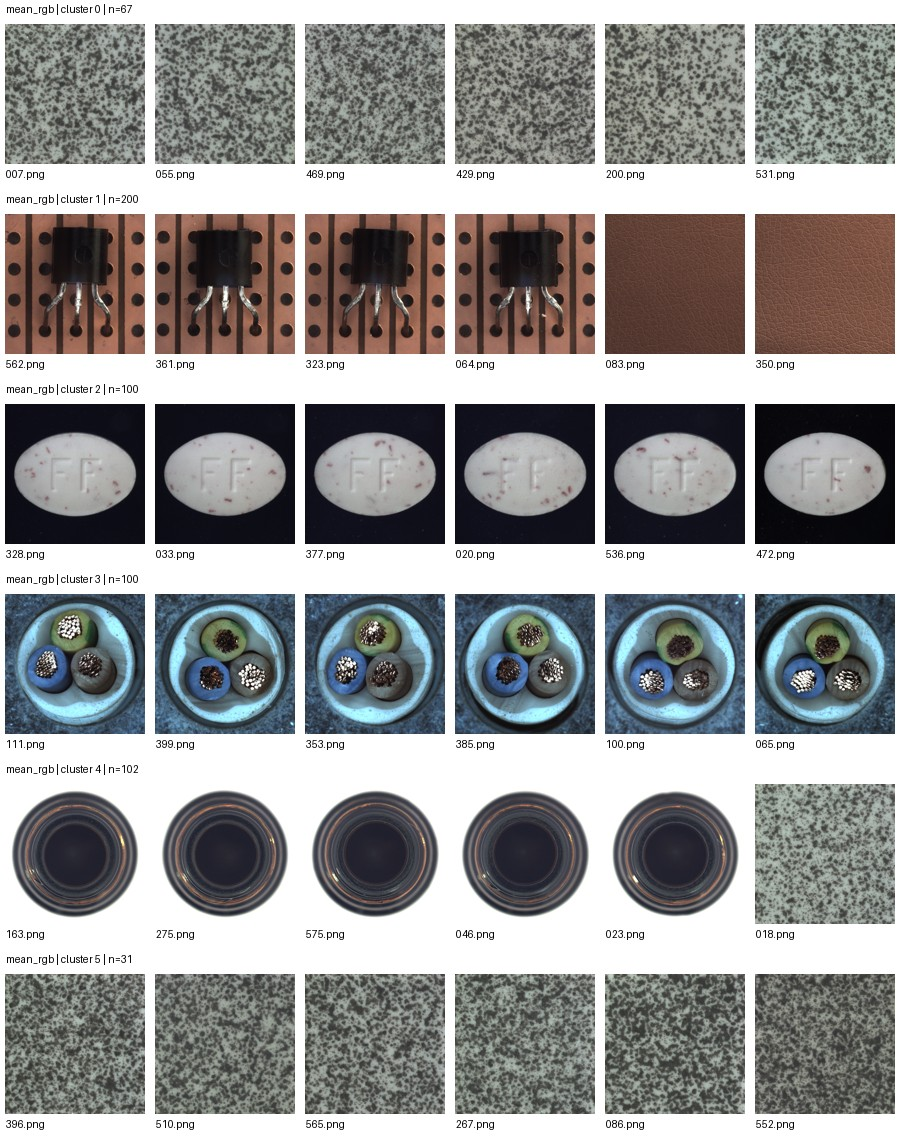

In [45]:
save_unlabeled_assignments("mean_rgb", rgb_primary)
show_cluster_gallery("mean_rgb", X_rgb, rgb_primary)


## 4. 方法 B：HOG 表示与 K-Means

### 4.1 特征定义与预处理

HOG 以局部梯度方向分布描述图像结构，并通过重叠块归一化处理局部对比度变化 [2, 6]。
本文首先将图像转换为灰度，并用 Lanczos 重采样统一为128×128；灰度像素转为浮点数并除以255。
随后在16×16像素的单元（cell）中统计9个方向区间，将相邻2×2单元组成块（block），采用 L2-Hys 归一化。

| 参数 | 方法 B 的设置 |
|---|---|
| 输入 | 128×128 单通道灰度图 |
| 数值范围 | 0～1；不启用平方根变换 |
| 梯度方向区间 | 9 |
| 单元大小 | 16×16像素 |
| 块大小 | 2×2单元，默认相邻块移动一个单元 |
| 块归一化 | L2-Hys；不再进行特征列标准化 |

每个方向上的单元数为 $128/16=8$，有效块位置为 $8-2+1=7$，故特征维度为
$d_B=7\times7\times2\times2\times9=1764$，即 $X^{(B)}\in\mathbb R^{600\times1764}$。
这些数值同时包含轮廓、纹理与背景结构信息，不应将 HOG 等同于物体分割或纯轮廓提取。

In [46]:
HOG_CONFIG = {
    "image_size": [128, 128], "orientations": 9,
    "pixels_per_cell": [16, 16], "cells_per_block": [2, 2],
    "block_norm": "L2-Hys", "transform_sqrt": False,
}
hog_rows = []
start = perf_counter()
with zipfile.ZipFile(DATA_PATH) as archive:
    for index, name in enumerate(image_names, start=1):
        with Image.open(io.BytesIO(archive.read(name))) as image:
            gray = image.convert("L").resize(tuple(HOG_CONFIG["image_size"]), Image.Resampling.LANCZOS)
        pixels = np.asarray(gray, dtype=np.float32) / 255.0
        vector = hog(
            pixels, orientations=HOG_CONFIG["orientations"],
            pixels_per_cell=tuple(HOG_CONFIG["pixels_per_cell"]),
            cells_per_block=tuple(HOG_CONFIG["cells_per_block"]),
            block_norm=HOG_CONFIG["block_norm"], transform_sqrt=HOG_CONFIG["transform_sqrt"],
            feature_vector=True,
        )
        hog_rows.append(vector)
        if index % 100 == 0:
            print(f"方法 B：已提取 {index}/{len(image_names)} 张图像")

X_hog = np.asarray(hog_rows, dtype=np.float32)
hog_extraction_seconds = perf_counter() - start
assert X_hog.shape == (600, 1764) and np.isfinite(X_hog).all()
print("方法 B 特征矩阵:", X_hog.shape)


方法 B：已提取 100/600 张图像
方法 B：已提取 200/600 张图像
方法 B：已提取 300/600 张图像
方法 B：已提取 400/600 张图像
方法 B：已提取 500/600 张图像
方法 B：已提取 600/600 张图像
方法 B 特征矩阵: (600, 1764)


### 4.2 模型训练

以 $X^{(B)}$ 为输入，独立生成 `hog_runs` 与主实验模型。聚类超参数、主实验种子和重复实验种子均与方法 A 相同。由于维度和数值尺度不同，两种表示的组内平方距离和不直接比较。

In [47]:
hog_runs = fit_kmeans_runs(X_hog)
hog_primary = hog_runs[CONFIG["primary_seed"]]
print("方法 B 聚类中心形状:", hog_primary["model"].cluster_centers_.shape)
print("方法 B 主实验迭代次数:", hog_primary["n_iter"])


方法 B 聚类中心形状: (6, 1764)
方法 B 主实验迭代次数: 2


### 4.3 簇规模与代表样本

采用与方法 A 相同的抽样规则，输出至 `results/method_b_hog/`。本阶段仍不读取真实标签。

| 簇编号 | 样本数 |
| --- | --- |
| 0 | 100 |
| 1 | 100 |
| 2 | 100 |
| 3 | 100 |
| 4 | 100 |
| 5 | 100 |

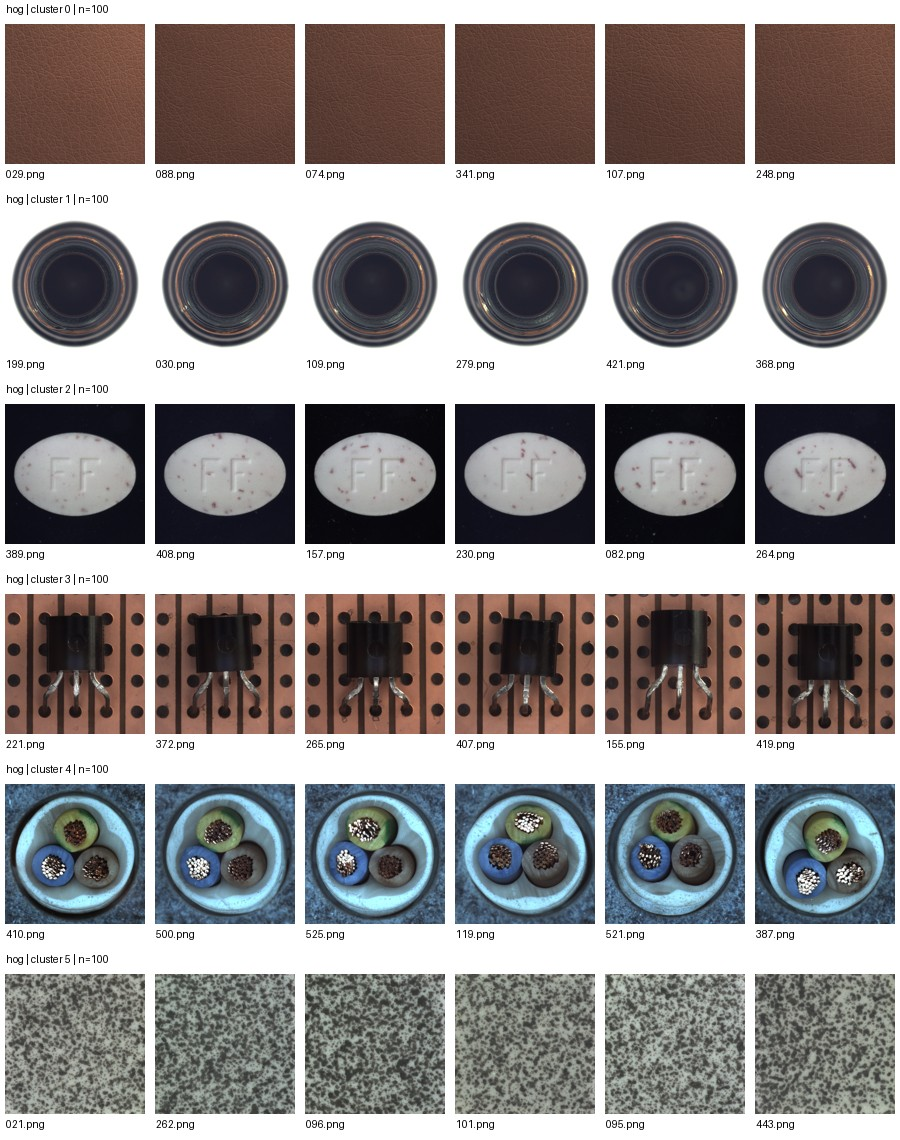

In [48]:
save_unlabeled_assignments("hog", hog_primary)
show_cluster_gallery("hog", X_hog, hog_primary)


## 5. 统一评价协议与分方法结果

### 5.1 评价指标与标签对齐

所有聚类均已完成，此时加载 `cluster_labels.json`，按文件名构造真实标签向量 $y$。
评价不重新拟合模型，也不改变已有簇指派。

| 指标 | 定义及解释 |
|---|---|
| ACC | 对簇与类别进行最佳一对一指派后的正确比例；不直接比较类别编号与簇编号 |
| ARI | 对样本对的一致性作随机机会修正；1表示完全一致，随机分组的期望约为0，可为负 [3] |
| NMI | 归一化互信息；本文显式使用熵的算术平均进行归一化 [5] |
| 轮廓系数 | 基于所选特征空间的簇内距离及最近其他簇距离；无需真实标签 [4] |

$$\operatorname{ACC}=\frac{1}{N}\max_{\pi}\sum_i\mathbf1[y_i=\pi(z_i)],\qquad
\operatorname{NMI}=\frac{2\operatorname{MI}(Y,Z)}{H(Y)+H(Z)}.$$

对样本 $i$，令 $a(i)$ 为同簇其他样本的平均距离、$b(i)$ 为最近其他簇的平均距离，则
$s(i)=[b(i)-a(i)]/\max\{a(i),b(i)\}$，整体轮廓系数取样本均值。
轮廓系数描述几何分离程度，不等同于语义类别恢复能力。
ACC 的一对一匹配通过 SciPy 线性指派接口求解 [7]。

In [49]:
with zipfile.ZipFile(DATA_PATH) as archive:
    ground_truth = json.loads(archive.read("Cluster/cluster_labels.json"))
if set(ground_truth) != set(filenames):
    raise ValueError("标签文件与图像文件名集合不一致。")
class_names = sorted(set(ground_truth.values()))
class_index = {name: index for index, name in enumerate(class_names)}
y_true = np.asarray([class_index[ground_truth[name]] for name in filenames])
class_counts = Counter(ground_truth.values())
if len(class_names) != 6 or any(count != 100 for count in class_counts.values()):
    raise ValueError("标签分布与课程数据说明不一致。")
show_table(
    [{"class": name, "count": class_counts[name]} for name in class_names],
    [("class", "真实类别"), ("count", "样本数")],
)


| 真实类别 | 样本数 |
| --- | --- |
| bottle | 100 |
| cable | 100 |
| leather | 100 |
| pill | 100 |
| tile | 100 |
| transistor | 100 |

In [50]:
def evaluate_partition(true_labels, cluster_ids, category_names):
    counts = np.zeros((len(category_names), CONFIG["n_clusters"]), dtype=np.int64)
    np.add.at(counts, (true_labels, cluster_ids), 1)
    rows, columns = linear_sum_assignment(counts, maximize=True)
    mapping = {int(column): category_names[row] for row, column in zip(rows, columns)}
    correct = int(counts[rows, columns].sum())
    metrics = {
        "ACC": correct / len(true_labels),
        "ARI": float(adjusted_rand_score(true_labels, cluster_ids)),
        "NMI": float(normalized_mutual_info_score(true_labels, cluster_ids, average_method="arithmetic")),
        "correct": correct, "incorrect": len(true_labels) - correct,
    }
    return metrics, counts, mapping


def evaluate_method(method, matrix, runs, true_labels, category_names):
    primary = runs[CONFIG["primary_seed"]]
    metrics, counts, mapping = evaluate_partition(true_labels, primary["cluster_ids"], category_names)
    metrics["silhouette"] = float(silhouette_score(matrix, primary["cluster_ids"], metric="euclidean"))
    stability = []
    for seed in CONFIG["stability_seeds"]:
        run = runs[seed]
        seed_metrics, _, _ = evaluate_partition(true_labels, run["cluster_ids"], category_names)
        stability.append({
            "method": method, "seed": seed, "n_iter": run["n_iter"],
            "training_seconds": run["training_seconds"],
            **{key: seed_metrics[key] for key in ("ACC", "ARI", "NMI")},
        })
    directory = METHOD_DIRS[method]
    (directory / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    count_rows = [
        {"true_class": name, **{f"cluster_{k}": int(counts[i, k]) for k in range(6)}}
        for i, name in enumerate(category_names)
    ]
    write_csv(directory / "contingency.csv", count_rows, list(count_rows[0]))
    write_csv(directory / "seed_stability.csv", stability, list(stability[0]))
    show_table([metrics], [("ACC", "ACC"), ("ARI", "ARI"), ("NMI", "NMI"), ("silhouette", "轮廓系数"), ("incorrect", "错误数")])
    return {"metrics": metrics, "counts": counts, "mapping": mapping, "stability": stability}


### 5.2 方法 A 的定量结果

对第3节已经生成的模型及指派进行评价，结果写入 `results/method_a_mean_rgb/`。

In [51]:
rgb_evaluation = evaluate_method("mean_rgb", X_rgb, rgb_runs, y_true, class_names)


| ACC | ARI | NMI | 轮廓系数 | 错误数 |
| --- | --- | --- | --- | --- |
| 0.7783 | 0.7728 | 0.8941 | 0.7468 | 133 |

### 5.3 方法 B 的定量结果

采用完全相同的评价实现，结果写入 `results/method_b_hog/`。两种方法的 ACC 只在各自完成簇—类别匹配后比较。

In [52]:
hog_evaluation = evaluate_method("hog", X_hog, hog_runs, y_true, class_names)


| ACC | ARI | NMI | 轮廓系数 | 错误数 |
| --- | --- | --- | --- | --- |
| 1.0000 | 1.0000 | 1.0000 | 0.4926 | 0 |

## 6. 对照实验与随机初始化稳定性

### 6.1 主实验结果与类别混淆

本节将两条方法流程的结果汇总。主实验种子固定为42；ACC、ARI、NMI 和轮廓系数均按0～1或−1～1的原始数值报告，而非百分数。

In [53]:
# 在分方法训练及评价完成后，才构造用于汇总展示的容器。
features = {"mean_rgb": X_rgb, "hog": X_hog}
evaluations = {"mean_rgb": rgb_evaluation, "hog": hog_evaluation}
primary_assignments = {"mean_rgb": rgb_primary["cluster_ids"], "hog": hog_primary["cluster_ids"]}
primary_metrics = {method: result["metrics"] for method, result in evaluations.items()}
contingency = {method: result["counts"] for method, result in evaluations.items()}
mappings = {method: result["mapping"] for method, result in evaluations.items()}
metric_rows = [{"method": method, **metrics} for method, metrics in primary_metrics.items()]
write_csv(COMPARISON_DIR / "metrics.csv", metric_rows, list(metric_rows[0]))
show_table(metric_rows, [
    ("method", "方法"), ("ACC", "ACC"), ("ARI", "ARI"), ("NMI", "NMI"),
    ("silhouette", "轮廓系数"), ("incorrect", "匹配后错误数"),
])

prediction_rows, audit_rows = [], []
for index, filename in enumerate(filenames):
    prediction = {"filename": filename}
    audit = {"filename": filename, "true_class": ground_truth[filename]}
    for method in features:
        cluster = int(primary_assignments[method][index])
        prediction[f"{method}_cluster"] = cluster
        audit[f"{method}_cluster"] = cluster
        audit[f"{method}_matched_class"] = mappings[method][cluster]
        audit[f"{method}_correct"] = int(mappings[method][cluster] == ground_truth[filename])
    prediction_rows.append(prediction)
    audit_rows.append(audit)
write_csv(COMPARISON_DIR / "cluster_assignments.csv", prediction_rows, list(prediction_rows[0]))
write_csv(COMPARISON_DIR / "sample_evaluation.csv", audit_rows, list(audit_rows[0]))


| 方法 | ACC | ARI | NMI | 轮廓系数 | 匹配后错误数 |
| --- | --- | --- | --- | --- | --- |
| mean_rgb | 0.7783 | 0.7728 | 0.8941 | 0.7468 | 133 |
| hog | 1.0000 | 1.0000 | 1.0000 | 0.4926 | 0 |

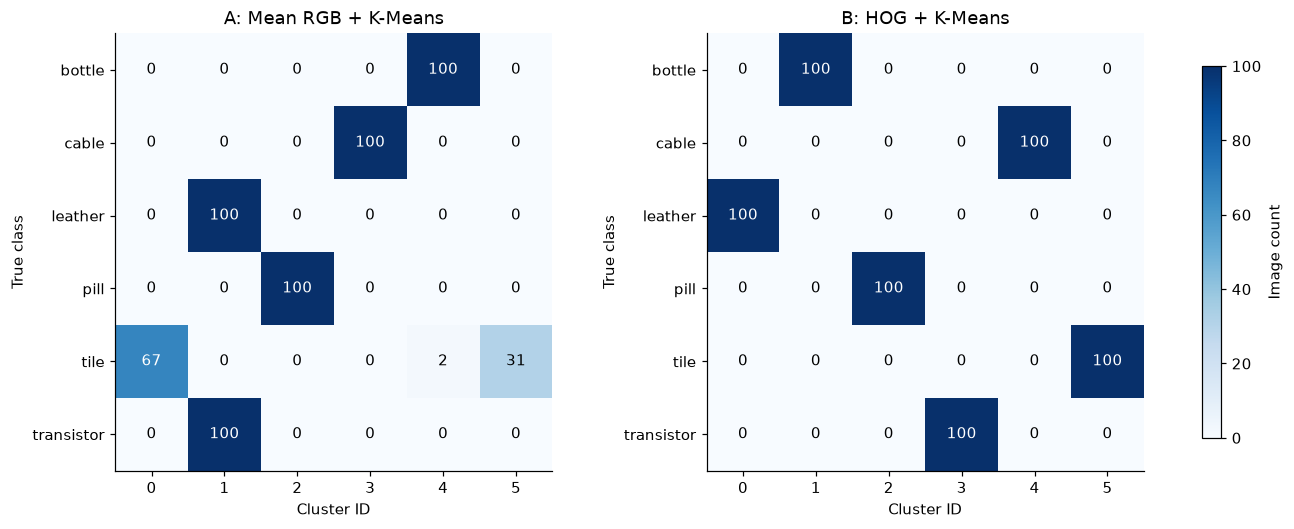

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), constrained_layout=True)
for ax, (method, counts) in zip(axes, contingency.items()):
    image = ax.imshow(counts, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks(range(6), [str(i) for i in range(6)])
    ax.set_yticks(range(6), class_names)
    ax.set_xlabel("Cluster ID")
    ax.set_ylabel("True class")
    ax.set_title(METHOD_NAMES[method])
    for row in range(6):
        for column in range(6):
            value = int(counts[row, column])
            ax.text(column, row, str(value), ha="center", va="center", color="white" if value > 50 else "black")
fig.colorbar(image, ax=axes, label="Image count", shrink=0.85)
fig.savefig(COMPARISON_DIR / "contingency_matrices.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


**图1.** 方法 A 与方法 B 的类别—簇交叉统计。行表示真实类别，列表示原始簇编号；各列不预先绑定类别，非对角位置上的计数不直接代表错误。

### 6.2 随机初始化稳定性

报告全部固定种子的结果，并以总体标准差（`ddof=0`）描述这五次指定运行的离散程度。该描述不构成独立数据集上的统计显著性检验。

In [55]:
stability_rows = rgb_evaluation["stability"] + hog_evaluation["stability"]
write_csv(COMPARISON_DIR / "seed_stability.csv", stability_rows, list(stability_rows[0]))
show_table(stability_rows, [("method", "方法"), ("seed", "种子"), ("ACC", "ACC"), ("ARI", "ARI"), ("NMI", "NMI")])

stability_summary = []
for method in features:
    selected = [row for row in stability_rows if row["method"] == method]
    accuracies = np.asarray([row["ACC"] for row in selected])
    stability_summary.append({
        "method": method, "ACC_mean": float(accuracies.mean()), "ACC_std": float(accuracies.std(ddof=0)),
        "ACC_min": float(accuracies.min()), "ACC_max": float(accuracies.max()),
        "ARI_mean": float(np.mean([row["ARI"] for row in selected])),
        "NMI_mean": float(np.mean([row["NMI"] for row in selected])),
    })
write_csv(COMPARISON_DIR / "stability_summary.csv", stability_summary, list(stability_summary[0]))
show_table(stability_summary, [("method", "方法"), ("ACC_mean", "ACC均值"), ("ACC_std", "ACC标准差"), ("ARI_mean", "ARI均值"), ("NMI_mean", "NMI均值")])


| 方法 | 种子 | ACC | ARI | NMI |
| --- | --- | --- | --- | --- |
| mean_rgb | 0 | 0.7783 | 0.7728 | 0.8941 |
| mean_rgb | 1 | 0.7783 | 0.7728 | 0.8941 |
| mean_rgb | 7 | 0.7783 | 0.7728 | 0.8941 |
| mean_rgb | 21 | 0.7783 | 0.7728 | 0.8941 |
| mean_rgb | 42 | 0.7783 | 0.7728 | 0.8941 |
| hog | 0 | 1.0000 | 1.0000 | 1.0000 |
| hog | 1 | 1.0000 | 1.0000 | 1.0000 |
| hog | 7 | 1.0000 | 1.0000 | 1.0000 |
| hog | 21 | 1.0000 | 1.0000 | 1.0000 |
| hog | 42 | 1.0000 | 1.0000 | 1.0000 |

| 方法 | ACC均值 | ACC标准差 | ARI均值 | NMI均值 |
| --- | --- | --- | --- | --- |
| mean_rgb | 0.7783 | 0.0000 | 0.7728 | 0.8941 |
| hog | 1.0000 | 0.0000 | 1.0000 | 1.0000 |

### 6.3 特征空间的二维投影

分别对两种特征执行二维 PCA，仅用于结果展示；聚类始终使用各自原始特征。不同表示的坐标轴分别计算，其坐标数值不能跨面板直接比较。

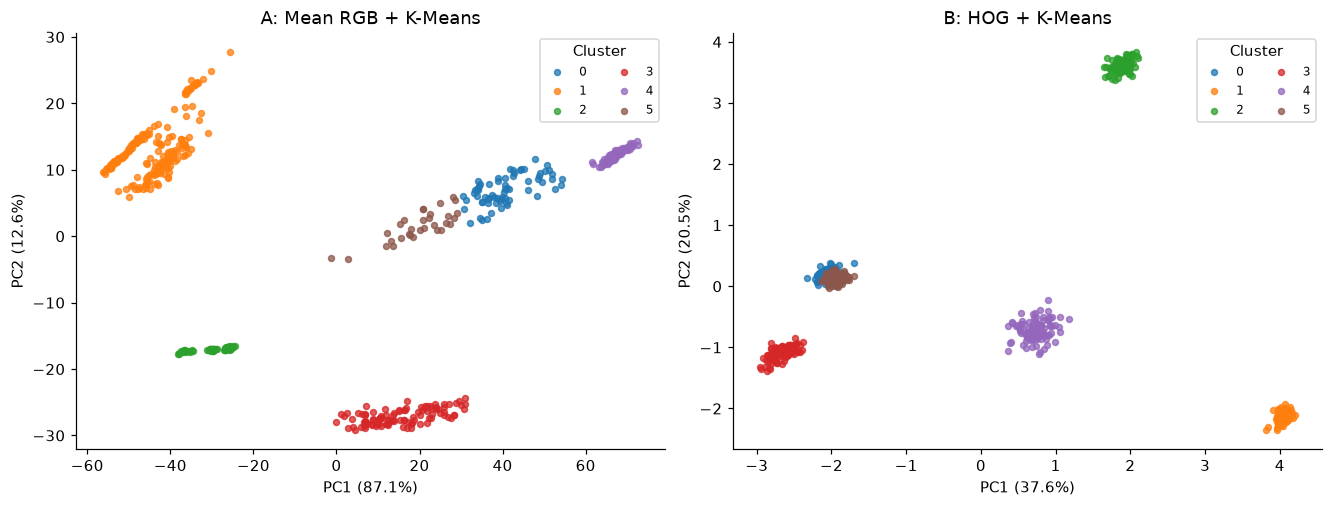

In [56]:
# PCA 只用于投影展示，聚类始终使用原始 3 维或 1764 维特征。
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
palette = plt.get_cmap("tab10")
pca_variance = {}
for ax, (method, matrix) in zip(axes, features.items()):
    pca = PCA(n_components=2, svd_solver="randomized", random_state=CONFIG["primary_seed"])
    projected = pca.fit_transform(matrix)
    pca_variance[method] = pca.explained_variance_ratio_.tolist()
    labels = primary_assignments[method]
    for cluster in range(6):
        indices = labels == cluster
        ax.scatter(projected[indices, 0], projected[indices, 1], s=15, alpha=0.75, color=palette(cluster), label=str(cluster))
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
    ax.set_title(METHOD_NAMES[method])
    ax.legend(title="Cluster", fontsize=8, ncols=2)
fig.savefig(COMPARISON_DIR / "pca_projection.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


**图2.** 两种特征的二维 PCA 投影，颜色表示预测簇编号。轴标签给出相应主成分的方差解释率；投影重叠不能单独用于判定高维聚类是否正确。

## 7. 讨论与局限

以下讨论由实际运行结果生成，按类别恢复、特征解释、内部指标、初始化稳定性及适用范围展开。

In [57]:
rgb_result, hog_result = primary_metrics["mean_rgb"], primary_metrics["hog"]
rgb_counts = contingency["mean_rgb"]
shared_cluster = int(np.argmax(rgb_counts[class_index["leather"]] + rgb_counts[class_index["transistor"]]))
tile_distribution = {int(k): int(value) for k, value in enumerate(rgb_counts[class_index["tile"]]) if value}
analysis_sections = [
    "### 7.1 类别结构的恢复\n\n"
    f"方法 A 的 ACC、ARI、NMI 分别为 {rgb_result['ACC']:.4f}、{rgb_result['ARI']:.4f}、{rgb_result['NMI']:.4f}，"
    f"最佳一对一匹配后有 {rgb_result['incorrect']} 张图像未对应其真实类别；"
    f"方法 B 的三项指标分别为 {hog_result['ACC']:.4f}、{hog_result['ARI']:.4f}、{hog_result['NMI']:.4f}。"
    "结合图1，可判断两种表示对当前类别划分的恢复程度存在差异。",
    "### 7.2 方法 A 的混淆模式与表示限制\n\n"
    f"方法 A 的簇 {shared_cluster} 同时包含 {rgb_counts[class_index['leather'], shared_cluster]} 张皮革与 "
    f"{rgb_counts[class_index['transistor'], shared_cluster]} 张晶体管；瓷砖分布于 {tile_distribution}（簇编号：样本数）。"
    "全局均值将像素位置聚合掉，整体色彩接近的物体可能被合并，类内亮度变化也可能造成分裂。"
    "HOG 方案则保留局部方向与空间分布。不过，两方案同时在灰度化、分辨率、维度和归一化方式上存在差异，"
    "因此该对照支持表示方案整体效果的比较，不能将提升单独归因于某一个处理环节。",
    "### 7.3 内部几何指标与语义类别的一致性\n\n"
    f"方法 A 的轮廓系数为 {rgb_result['silhouette']:.4f}，高于方法 B 的 {hog_result['silhouette']:.4f}，"
    "但外部类别一致性指标较低。这说明给定特征空间中的紧致、分离结构未必对应语义类别，"
    "且不同特征表示改变了距离几何，不能仅根据轮廓系数判断方案优劣。"
    f"方法 B 前两主成分合计解释 {sum(pca_variance['hog']):.2%} 的方差；图2中的部分投影重叠不否定高维空间中的分组结果。",
    "### 7.4 初始化敏感性\n\n" + "；".join(
        f"{METHOD_NAMES[row['method']]} 在五个固定种子上的 ACC 均值为 {row['ACC_mean']:.4f}，"
        f"标准差为 {row['ACC_std']:.4f}，范围为 [{row['ACC_min']:.4f}, {row['ACC_max']:.4f}]"
        for row in stability_summary
    ) + "。该结果仅刻画当前数据、参数和所列种子下的稳定性，不代表所有初始化的表现。",
]
analysis_text = "\n\n".join(analysis_sections)
display(Markdown(analysis_text))
(RESULTS_DIR / "analysis.md").write_text("# 讨论与局限\n\n" + analysis_text + "\n", encoding="utf-8")


### 7.1 类别结构的恢复

方法 A 的 ACC、ARI、NMI 分别为 0.7783、0.7728、0.8941，最佳一对一匹配后有 133 张图像未对应其真实类别；方法 B 的三项指标分别为 1.0000、1.0000、1.0000。结合图1，可判断两种表示对当前类别划分的恢复程度存在差异。

### 7.2 方法 A 的混淆模式与表示限制

方法 A 的簇 1 同时包含 100 张皮革与 100 张晶体管；瓷砖分布于 {0: 67, 4: 2, 5: 31}（簇编号：样本数）。全局均值将像素位置聚合掉，整体色彩接近的物体可能被合并，类内亮度变化也可能造成分裂。HOG 方案则保留局部方向与空间分布。不过，两方案同时在灰度化、分辨率、维度和归一化方式上存在差异，因此该对照支持表示方案整体效果的比较，不能将提升单独归因于某一个处理环节。

### 7.3 内部几何指标与语义类别的一致性

方法 A 的轮廓系数为 0.7468，高于方法 B 的 0.4926，但外部类别一致性指标较低。这说明给定特征空间中的紧致、分离结构未必对应语义类别，且不同特征表示改变了距离几何，不能仅根据轮廓系数判断方案优劣。方法 B 前两主成分合计解释 58.16% 的方差；图2中的部分投影重叠不否定高维空间中的分组结果。

### 7.4 初始化敏感性

A: Mean RGB + K-Means 在五个固定种子上的 ACC 均值为 0.7783，标准差为 0.0000，范围为 [0.7783, 0.7783]；B: HOG + K-Means 在五个固定种子上的 ACC 均值为 1.0000，标准差为 0.0000，范围为 [1.0000, 1.0000]。该结果仅刻画当前数据、参数和所列种子下的稳定性，不代表所有初始化的表现。

778

## 8. 结论与复现记录

在相同 K-Means 设置下，方法 B 在本数据上的外部评价指标高于方法 A，说明局部结构表示对当前类别区分具有更强的适用性。
颜色方案的较高轮廓系数同时表明，内部几何结构与语义一致性需要分别评价。
该结论受到数据规模、拍摄条件及所选特征参数的限制，不外推为一般图像聚类任务的性能保证。

复现记录包含数据摘要、软件版本、公共配置、分方法特征参数、主实验指标、五个随机种子结果和逐图像核对表。
提取耗时包含各方法自己的解码与特征计算，运行时间随系统状态变化，仅用于记录计算开销。

In [58]:
experiment_record = {
    "config": CONFIG,
    "methods": {
        "mean_rgb": {"id": "A", "feature": "channel_mean", "dimension": 3, "normalization": "none"},
        "hog": {"id": "B", "feature": "HOG", "dimension": 1764, "feature_parameters": HOG_CONFIG},
    },
    "environment": environment,
    "dataset": {"filename": DATA_PATH.name, "sha256": dataset_sha256, "samples": len(filenames)},
    "feature_dimensions": {"mean_rgb": int(X_rgb.shape[1]), "hog": int(X_hog.shape[1])},
    "extraction_seconds_by_method": {"mean_rgb": rgb_extraction_seconds, "hog": hog_extraction_seconds},
    "primary_metrics": primary_metrics,
    "evaluation_cluster_to_class_mapping": mappings,
    "pca_explained_variance_ratio": pca_variance,
}
(RESULTS_DIR / "experiment.json").write_text(json.dumps(experiment_record, ensure_ascii=False, indent=2), encoding="utf-8")
print("复现记录：results/experiment.json")
print("方法 A 结果：results/method_a_mean_rgb/")
print("方法 B 结果：results/method_b_hog/")
print("统一比较结果：results/comparison/")


复现记录：results/experiment.json
方法 A 结果：results/method_a_mean_rgb/
方法 B 结果：results/method_b_hog/
统一比较结果：results/comparison/


## 9. 参考文献

[1] Lloyd S P. [Least Squares Quantization in PCM](https://doi.org/10.1109/TIT.1982.1056489). *IEEE Transactions on Information Theory*, 1982, 28(2). DOI: 10.1109/TIT.1982.1056489.

[2] Dalal N, Triggs B. [Histograms of Oriented Gradients for Human Detection](https://lear.inrialpes.fr/people/triggs/pubs/Dalal-cvpr05.pdf). *Proceedings of CVPR*, 2005. DOI: 10.1109/CVPR.2005.177.

[3] Hubert L, Arabie P. [Comparing Partitions](https://link.springer.com/article/10.1007/BF01908075). *Journal of Classification*, 1985, 2: 193–218.

[4] Rousseeuw P J. [Silhouettes: A Graphical Aid to the Interpretation and Validation of Cluster Analysis](https://wis.kuleuven.be/stat/robust/papers/publications-1987/rousseeuw-silhouettes-jcam-sciencedirectopenarchiv.pdf/view). *Journal of Computational and Applied Mathematics*, 1987, 20: 53–65.

[5] scikit-learn developers. [Clustering: K-Means and Clustering Performance Evaluation](https://scikit-learn.org/stable/modules/clustering.html). 软件实现与指标定义，访问日期：2026-10-27。

[6] scikit-image developers. [HOG API Documentation](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.hog). 软件实现与参数定义，访问日期：2026-10-27。

[7] SciPy developers. [Linear Sum Assignment](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html). 最佳一对一指派接口，访问日期：2026-10-27。